# HW2 — Uniform Convergence and the Limits of Learning

**Statistical and Machine Learning** — M2 IMDS  
Université de Haute-Alsace

Omar Chellihi




In [29]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 2026

TOL = 1e-12

def pos(a):
    """Zero estimates cannot be drawn on a log axis: replace them by NaN (not plotted)."""
    a = np.asarray(a, dtype=float)
    return np.where(a > 0, a, np.nan)

In [30]:
def make_class(K):
    """True risks p_1, ..., p_K of a finite class H, evenly spaced in [0.05, 0.5]."""
    return np.linspace(0.05, 0.5, K)

P_BASE  = make_class(10)       # p = 0.05, 0.10, ..., 0.50
J_FIXED = 5                    # fixed hypothesis for Q1-Q2 (p = 0.30)
EPS     = 0.05                 # accuracy level
DELTA   = 0.05                 # confidence level (Q5)
H_SIZES = [5, 10, 50, 100, 500]
N_VALUES = [50, 200, 1000]     # domain sizes (Parts II-III)

print("p_j =", np.round(P_BASE, 2))
print("fixed hypothesis: p =", P_BASE[J_FIXED])
print("Hoeffding bound < 1 as soon as m >", np.log(2) / (2 * EPS**2))

p_j = [0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5 ]
fixed hypothesis: p = 0.3
Hoeffding bound < 1 as soon as m > 138.62943611198904


---
# Part I – Simulating Uniform Convergence



## 1. Empirical risk as a random variable



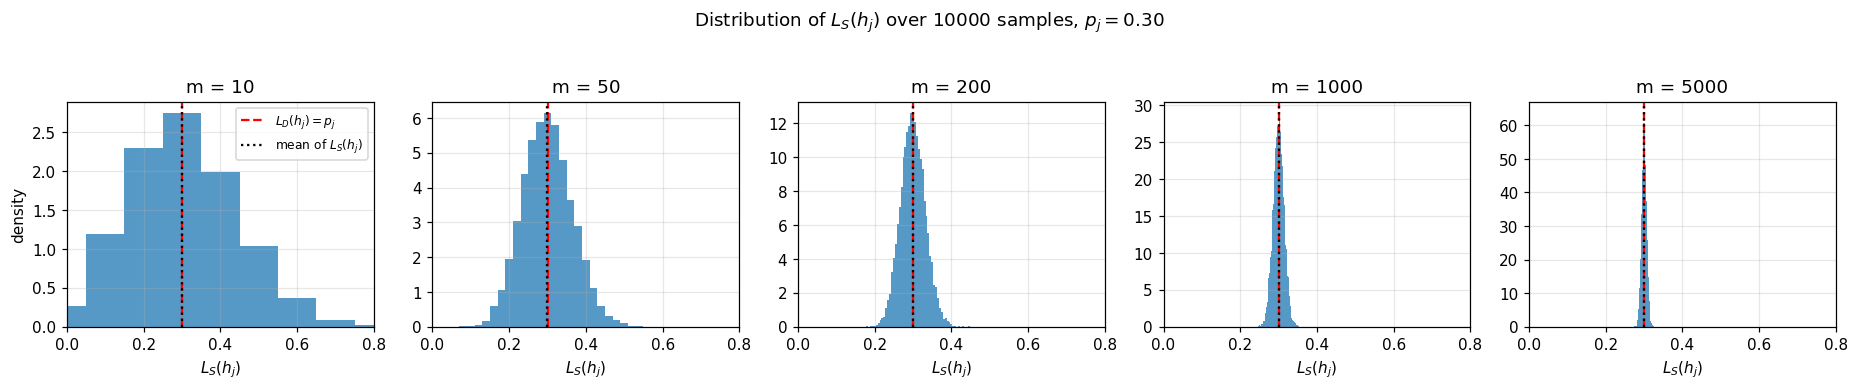

     m |  mean L_S | |mean - p| |  std L_S | sqrt(p(1-p)/m)
    10 |    0.3007 |     0.0007 |   0.1434 |         0.1449
    50 |    0.2997 |     0.0003 |   0.0643 |         0.0648
   200 |    0.2995 |     0.0005 |   0.0321 |         0.0324
  1000 |    0.3000 |     0.0000 |   0.0145 |         0.0145
  5000 |    0.3000 |     0.0000 |   0.0065 |         0.0065


In [31]:
rng = np.random.default_rng(SEED + 1)
R1 = 10_000                                   # Monte-Carlo repetitions
p = P_BASE[J_FIXED]
m_values_q1 = [10, 50, 200, 1000, 5000]

fig, axes = plt.subplots(1, len(m_values_q1), figsize=(17, 3.4), sharex=True)
rows = []
for ax, m in zip(axes, m_values_q1):
    E = rng.binomial(m, p, size=R1)           # (a) E_j ~ Binomial(m, p_j), R1 times
    LS = E / m                                # (b) L_S(h_j) = E_j / m

    step = max(1, (E.max() - E.min()) // 40)
    bins = (np.arange(E.min(), E.max() + step + 1, step) - 0.5) / m
    ax.hist(LS, bins=bins, density=True, color="tab:blue", alpha=0.75)
    ax.axvline(p, color="red", ls="--", lw=1.5, label=r"$L_D(h_j)=p_j$")
    ax.axvline(LS.mean(), color="k", ls=":", lw=1.5, label=r"mean of $L_S(h_j)$")
    ax.set_title(f"m = {m}")
    ax.set_xlabel(r"$L_S(h_j)$")
    ax.set_xlim(0, 0.8)
    rows.append((m, LS.mean(), LS.std(ddof=1), np.sqrt(p * (1 - p) / m)))
axes[0].set_ylabel("density")
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle(rf"Distribution of $L_S(h_j)$ over {R1} samples, $p_j = {p:.2f}$", y=1.03)
plt.tight_layout()
plt.show()

# (d) empirical mean vs true risk, and spread vs sqrt(p(1-p)/m)
print(f"{'m':>6} | {'mean L_S':>9} | {'|mean - p|':>10} | {'std L_S':>8} | {'sqrt(p(1-p)/m)':>14}")
for m, mu, sd, sd_th in rows:
    print(f"{m:>6} | {mu:>9.4f} | {abs(mu - p):>10.4f} | {sd:>8.4f} | {sd_th:>14.4f}")

**Interpretation.**

- **Mean vs true risk.** For every $m$ the empirical mean of $L_S(h_j)$ equals $p_j = 0.30$ up to $0.001$: $L_S(h_j)$ is an unbiased estimator of $L_D(h_j)$ ($\mathbb{E}[E_j] = m p_j$).
- **Variability.** The standard deviation drops from $0.143$ ($m=10$) to $0.064$, $0.032$, $0.0145$ and $0.0065$ ($m=5000$), matching $\sqrt{p_j(1-p_j)/m}$ in every case: it decreases like $1/\sqrt{m}$ (multiplying $m$ by 100 divides it by $\approx 10$).
- For $m=10$ the distribution is discrete (values $k/10$) and wide: a sample of 10 points can easily give $L_S = 0$ or $L_S = 0.6$ for a hypothesis whose true risk is $0.3$. For large $m$ the histogram becomes narrow and bell-shaped, concentrated around $p_j$: the empirical risk becomes a reliable estimate of the true risk.

## 2. Deviation between empirical and true risk



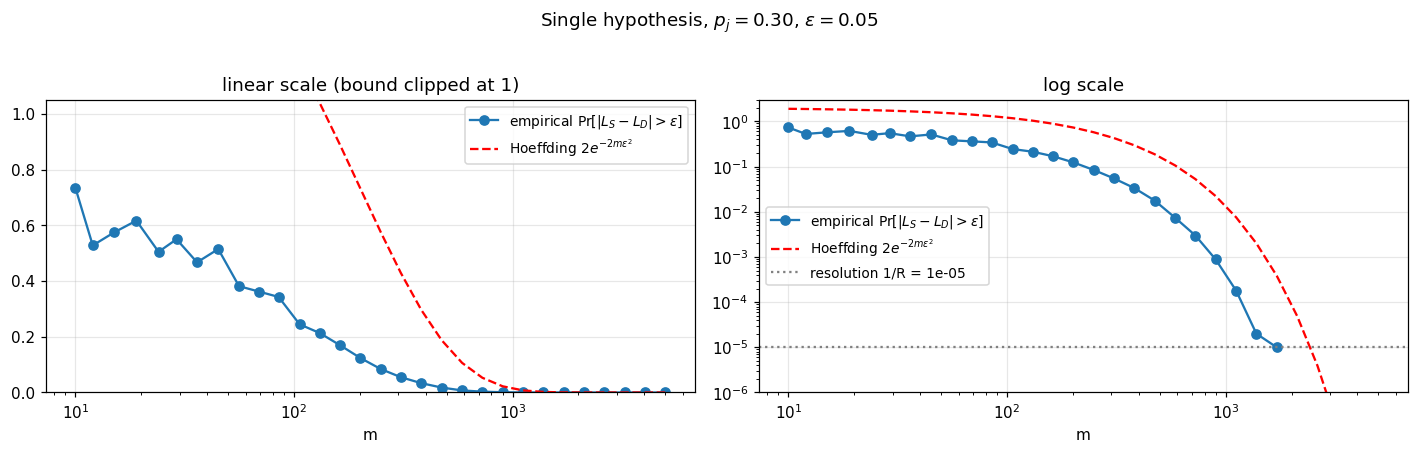

    m |  empirical |  Hoeffding | bound / empirical
   10 |    0.73382 |    1.90246 |              2.59
   45 |    0.51468 |    1.59703 |              3.10
  106 |    0.24468 |    1.17721 |              4.81
  201 |    0.12387 |    0.73209 |              5.91
  308 |    0.05486 |    0.42876 |              7.82
  473 |    0.01774 |    0.18790 |             10.59
  900 |    0.00088 |    0.02222 |             25.25
 1382 |    0.00002 |    0.00200 |             99.78


In [32]:
rng = np.random.default_rng(SEED + 2)
R2 = 100_000                                  # resolves probabilities down to ~1e-5
p = P_BASE[J_FIXED]
m_grid = np.unique(np.round(np.geomspace(10, 5000, 30)).astype(int))

prob_single = np.empty(len(m_grid))
for i, m in enumerate(m_grid):
    LS = rng.binomial(m, p, size=R2) / m
    dev = np.abs(LS - p)                      # |L_S(h_j) - L_D(h_j)| for every simulated sample
    prob_single[i] = np.mean(dev > EPS + TOL)
hoeffding = 2 * np.exp(-2 * m_grid * EPS**2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, logy in zip(axes, [False, True]):
    ax.plot(m_grid, pos(prob_single) if logy else prob_single, "o-",
            label=r"empirical $\Pr[|L_S-L_D|>\epsilon]$")
    ax.plot(m_grid, hoeffding, "--", color="red", label=r"Hoeffding $2e^{-2m\epsilon^2}$")
    ax.set_xscale("log")
    ax.set_xlabel("m")
    if logy:
        ax.set_yscale("log")
        ax.set_ylim(1e-6, 3)
        ax.axhline(1 / R2, color="gray", ls=":", label=f"resolution 1/R = {1/R2:.0e}")
        ax.set_title("log scale")
    else:
        ax.set_ylim(0, 1.05)
        ax.set_title("linear scale (bound clipped at 1)")
    ax.legend(fontsize=9)
fig.suptitle(rf"Single hypothesis, $p_j={p:.2f}$, $\epsilon={EPS}$", y=1.02)
plt.tight_layout()
plt.show()

print(f"{'m':>5} | {'empirical':>10} | {'Hoeffding':>10} | {'bound / empirical':>17}")
for i in sorted({int(np.argmin(np.abs(m_grid - t))) for t in (10, 50, 100, 200, 300, 500, 1000, 1500)}):
    m, pe, hb = m_grid[i], prob_single[i], hoeffding[i]
    ratio = hb / pe if pe > 0 else np.inf
    print(f"{m:>5} | {pe:>10.5f} | {hb:>10.5f} | {ratio:>17.2f}")

**Interpretation.**

- **The bound is valid:** for every $m$ the Hoeffding bound lies above the empirical probability.
- **It is not exact but conservative.** It is vacuous ($\geq 1$) for $m \leq 138$, while the actual probability is already $0.24$ at $m \approx 106$. Where it is informative, the ratio bound / empirical keeps increasing: $\approx 6$ at $m \approx 200$, $\approx 25$ at $m = 900$, $\approx 100$ at $m \approx 1400$. Both quantities decay exponentially in $m$, but not at the same rate. Hoeffding only uses the fact that losses lie in $[0,1]$, i.e. the worst-case variance $1/4$ (attained at $p=1/2$), whereas here the variance is $p(1-p)=0.21$. The actual tail behaves (Gaussian approximation) like $e^{-m\epsilon^2/(2p(1-p))} = e^{-2.38\, m\epsilon^2}$ instead of $e^{-2m\epsilon^2}$, so the gap grows exponentially with $m$.
- **Zigzag for small $m$.** $L_S$ only takes values $k/m$, so the number of values counted as "$> \epsilon$" depends on where $p \pm \epsilon$ falls on this lattice. For $m=10$ only $k=3$ is within $\epsilon$ (probability $1-\Pr[E=3] = 0.73$); for $m=12$ both $k=3$ ($|0.25-0.3| = \epsilon$ exactly, not $>\epsilon$) and $k=4$ are within $\epsilon$, which gives the lower value $0.53$. The curve is therefore not monotone for small $m$, while the bound is smooth.

## 3. From one hypothesis to uniform convergence


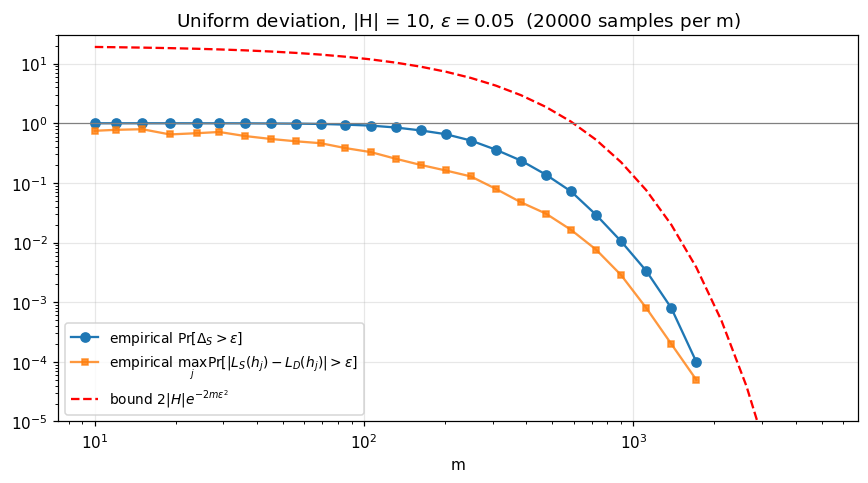

    m | Pr[Delta>eps] | max_j Pr_j | sum_j Pr_j |    bound
   10 |        0.9999 |     0.7480 |     5.5030 |  19.0246
   45 |        0.9922 |     0.5457 |     3.8470 |  15.9703
  106 |        0.9136 |     0.3282 |     2.1097 |  11.7721
  201 |        0.6560 |     0.1615 |     0.9901 |   7.3209
  308 |        0.3613 |     0.0798 |     0.4331 |   4.2876
  473 |        0.1378 |     0.0306 |     0.1462 |   1.8790
  900 |        0.0105 |     0.0029 |     0.0105 |   0.2222
 1382 |        0.0008 |     0.0002 |     0.0008 |   0.0200


In [33]:
rng = np.random.default_rng(SEED + 3)
R3 = 20_000
P = P_BASE
K = len(P)

prob_unif = np.empty(len(m_grid))
prob_each = np.empty((len(m_grid), K))
for i, m in enumerate(m_grid):
    E = rng.binomial(m, P, size=(R3, K))      # one row = one sample: L_S(h_1), ..., L_S(h_K)
    dev = np.abs(E / m - P)
    Delta = dev.max(axis=1)                   # Delta_S = max_h |L_S(h) - L_D(h)|
    prob_unif[i] = np.mean(Delta > EPS + TOL)
    prob_each[i] = np.mean(dev > EPS + TOL, axis=0)
bound_unif = 2 * K * np.exp(-2 * m_grid * EPS**2)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(m_grid, pos(prob_unif), "o-", label=r"empirical $\Pr[\Delta_S>\epsilon]$")
ax.plot(m_grid, pos(prob_each.max(axis=1)), "s-", ms=4, alpha=0.8,
        label=r"empirical $\max_j \Pr[|L_S(h_j)-L_D(h_j)|>\epsilon]$")
ax.plot(m_grid, bound_unif, "--", color="red", label=r"bound $2|H|e^{-2m\epsilon^2}$")
ax.axhline(1, color="gray", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_ylim(1e-5, 30)
ax.set_xlabel("m")
ax.set_title(rf"Uniform deviation, |H| = {K}, $\epsilon={EPS}$  ({R3} samples per m)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"{'m':>5} | {'Pr[Delta>eps]':>13} | {'max_j Pr_j':>10} | {'sum_j Pr_j':>10} | {'bound':>8}")
for i in sorted({int(np.argmin(np.abs(m_grid - t))) for t in (10, 50, 100, 200, 300, 500, 1000, 1500)}):
    print(f"{m_grid[i]:>5} | {prob_unif[i]:>13.4f} | {prob_each[i].max():>10.4f} | "
          f"{prob_each[i].sum():>10.4f} | {bound_unif[i]:>8.4f}")

**Interpretation.**

- **Uniform deviation is harder to control than a single deviation.** Since $\{|L_S(h_j)-L_D(h_j)|>\epsilon\} \subset \{\Delta_S>\epsilon\}$, we always have $\Pr[\Delta_S>\epsilon] \geq \max_j \Pr[\,|L_S(h_j)-L_D(h_j)|>\epsilon\,]$, and the gap is large: at $m\approx 200$, the worst hypothesis alone deviates with probability $0.16$, but at least one of the 10 hypotheses deviates with probability $0.66$. Uniform convergence requires *all* hypotheses to be within $\epsilon$ at the same time.
- **Where the bound loses.** The theoretical bound is obtained by $\Pr[\Delta_S>\epsilon] \leq \sum_j \Pr[|L_S(h_j)-L_D(h_j)|>\epsilon] \leq 2|H|e^{-2m\epsilon^2}$.
  - The union-bound step is crude for small $m$ (the sum is $5.5$ at $m=10$, much more than 1), but nearly tight for large $m$ ($0.0105$ vs $0.0105$ at $m=900$, $0.0008$ vs $0.0008$ at $m\approx1400$): large deviations are rare and almost never happen for two hypotheses on the same sample.
  - The remaining factor ($0.22$ vs $0.0105$ at $m=900$, i.e. $\approx 21$) comes from Hoeffding applied to each hypothesis, as in Q2.
- The bound is vacuous until $m > \ln(2|H|)/(2\epsilon^2) \approx 599$, against $\approx 139$ for one hypothesis: the factor $|H|$ delays the point where the guarantee becomes informative. The empirical probability is always below the bound.

## 4. Effect of the size of the hypothesis class



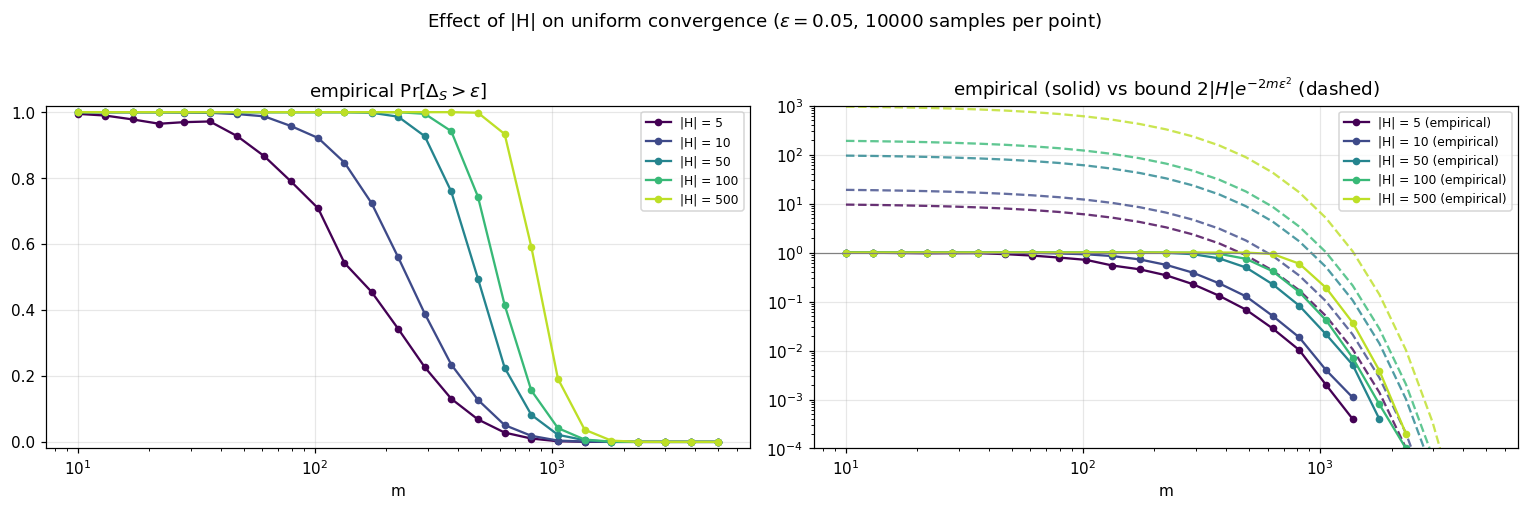

Pr[Delta_S > eps] at selected m
  |H| | m=  103 | m=  224 | m=  486 | m= 1057 | m= 1370
    5 |  0.7083 |  0.3431 |  0.0682 |  0.0020 |  0.0004
   10 |  0.9217 |  0.5601 |  0.1276 |  0.0040 |  0.0011
   50 |  1.0000 |  0.9863 |  0.4954 |  0.0215 |  0.0051
  100 |  1.0000 |  0.9999 |  0.7439 |  0.0418 |  0.0071
  500 |  1.0000 |  1.0000 |  0.9983 |  0.1914 |  0.0371


In [20]:
def prob_uniform_deviation(P, m, R, eps, rng):
    """Monte-Carlo estimate of Pr[Delta_S > eps] for a class with true risks P and sample size m."""
    E = rng.binomial(m, P, size=(R, len(P)))
    Delta = np.abs(E / m - P).max(axis=1)
    return np.mean(Delta > eps + TOL)

rng = np.random.default_rng(SEED + 4)
R4 = 10_000
m_grid4 = np.unique(np.round(np.geomspace(10, 5000, 25)).astype(int))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(H_SIZES)))

prob_by_H = {}
for K in H_SIZES:
    P = make_class(K)
    prob_by_H[K] = np.array([prob_uniform_deviation(P, m, R4, EPS, rng) for m in m_grid4])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for K, c in zip(H_SIZES, colors):
    axes[0].plot(m_grid4, prob_by_H[K], "o-", ms=4, color=c, label=f"|H| = {K}")
    axes[1].plot(m_grid4, pos(prob_by_H[K]), "o-", ms=4, color=c, label=f"|H| = {K} (empirical)")
    axes[1].plot(m_grid4, 2 * K * np.exp(-2 * m_grid4 * EPS**2), "--", color=c, alpha=0.8)
axes[0].set_title(r"empirical $\Pr[\Delta_S>\epsilon]$")
axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title(r"empirical (solid) vs bound $2|H|e^{-2m\epsilon^2}$ (dashed)")
axes[1].set_yscale("log"); axes[1].set_ylim(1e-4, 1e3)
axes[1].axhline(1, color="gray", lw=0.8)
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("m"); ax.legend(fontsize=8)
fig.suptitle(rf"Effect of |H| on uniform convergence ($\epsilon={EPS}$, {R4} samples per point)", y=1.02)
plt.tight_layout()
plt.show()

print("Pr[Delta_S > eps] at selected m")
sel = [int(np.argmin(np.abs(m_grid4 - t))) for t in (100, 200, 500, 1000, 1500)]
print(f"{'|H|':>5} | " + " | ".join(f"m={m_grid4[i]:>5}" for i in sel))
for K in H_SIZES:
    print(f"{K:>5} | " + " | ".join(f"{prob_by_H[K][i]:>7.4f}" for i in sel))

**Interpretation.**

- **How does increasing $|H|$ affect uniform convergence?** The curves are ordered by $|H|$ and shifted to the right: at $m\approx 486$, $\Pr[\Delta_S>\epsilon] = 0.07, 0.13, 0.49, 0.74, 0.998$ for $|H| = 5, 10, 50, 100, 500$. Each additional hypothesis is one more chance that some empirical risk deviates by more than $\epsilon$, so simultaneous control becomes harder.
- **Does a larger class require more data?** Yes: for a given target probability, the required $m$ increases with $|H|$. But the increase is moderate: the value of $m$ at which $\Pr[\Delta_S>\epsilon]$ falls to $0.5$ moves from $\approx150$ ($|H|=5$) to $\approx485$ ($|H|=50$) and $\approx850$ ($|H|=500$). Multiplying $|H|$ by 100 multiplies this sample size by less than 6.
- **Relation with $\log|H|$.** Each factor 10 on $|H|$ *adds* a roughly constant number of samples ($\approx 350$ here) instead of multiplying $m$: the required sample size grows like $\log|H|$. This is the dependence given by the bound: $2|H|e^{-2m\epsilon^2}\leq\delta \iff m \geq \frac{\ln(2|H|/\delta)}{2\epsilon^2}$, so multiplying $|H|$ by $c$ adds $\ln c/(2\epsilon^2)$ samples ($\approx 460$ for $c=10$). For the same reason, the point where the bound becomes non-vacuous, $\ln(2|H|)/(2\epsilon^2)$, moves from $\approx 461$ ($|H|=5$) to $\approx 1382$ ($|H|=500$). Q5 checks this dependence at a fixed $(\epsilon,\delta)$.
- On the right panel each empirical curve stays below its own bound for all $m$.

## 5. Experimental sample complexity



eps = 0.05, delta = 0.05, 10000 samples per tested m (tested m = 10, 20, ..., 5000)

  |H| | log|H| | m experimental | m theoretical | theory / exp
    5 |   1.61 |            520 |          1060 |         2.04
   10 |   2.30 |            640 |          1199 |         1.87
   50 |   3.91 |            920 |          1521 |         1.65
  100 |   4.61 |           1030 |          1659 |         1.61
  500 |   6.21 |           1310 |          1981 |         1.51

slope of m vs log|H|: experimental ~ 171, theoretical = 1/(2 eps^2) = 200


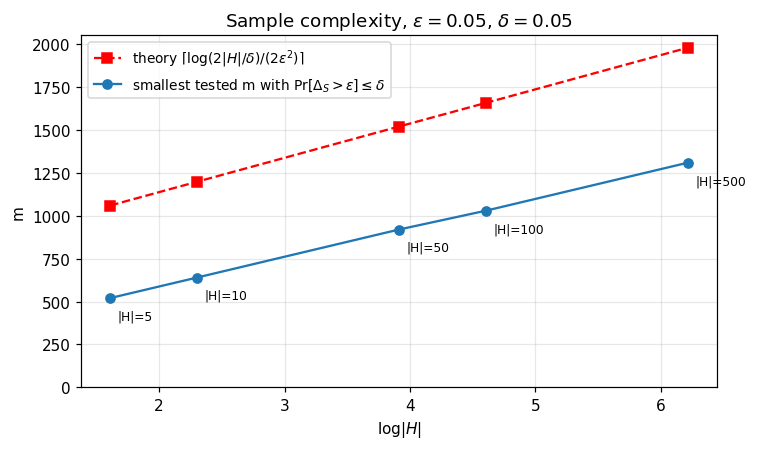

In [21]:
M_TESTED = np.arange(10, 5001, 10)          # tested sample sizes

def smallest_tested_m(P, eps, delta, R, rng, grid=M_TESTED, step=5):
    """Smallest m in `grid` with estimated Pr[Delta_S > eps] <= delta.
    Coarse scan (every `step`-th grid value) to bracket the crossing, then every grid value
    inside the bracket (Pr[Delta_S > eps] decreases with m, up to Monte-Carlo noise)."""
    prev = -1
    for i in range(0, len(grid), step):
        if prob_uniform_deviation(P, grid[i], R, eps, rng) <= delta:
            for j in range(prev + 1, i):
                if prob_uniform_deviation(P, grid[j], R, eps, rng) <= delta:
                    return grid[j]
            return grid[i]
        prev = i
    return np.nan

rng = np.random.default_rng(SEED + 5)
R5 = 10_000
m_exp = np.array([smallest_tested_m(make_class(K), EPS, DELTA, R5, rng) for K in H_SIZES])
m_th = np.ceil(np.log(2 * np.array(H_SIZES) / DELTA) / (2 * EPS**2)).astype(int)

print(f"eps = {EPS}, delta = {DELTA}, {R5} samples per tested m (tested m = 10, 20, ..., 5000)\n")
print(f"{'|H|':>5} | {'log|H|':>6} | {'m experimental':>14} | {'m theoretical':>13} | {'theory / exp':>12}")
for K, me, mt in zip(H_SIZES, m_exp, m_th):
    print(f"{K:>5} | {np.log(K):>6.2f} | {me:>14} | {mt:>13} | {mt / me:>12.2f}")

logH = np.log(H_SIZES)
slope_exp = np.polyfit(logH, m_exp, 1)[0]
print(f"\nslope of m vs log|H|: experimental ~ {slope_exp:.0f}, theoretical = 1/(2 eps^2) = {1/(2*EPS**2):.0f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(logH, m_th, "s--", color="red", label=r"theory $\lceil\log(2|H|/\delta)/(2\epsilon^2)\rceil$")
ax.plot(logH, m_exp, "o-", label=r"smallest tested m with $\Pr[\Delta_S>\epsilon]\leq\delta$")
for K, x, y in zip(H_SIZES, logH, m_exp):
    ax.annotate(f"|H|={K}", (x, y), textcoords="offset points", xytext=(5, -14), fontsize=8)
ax.set_xlabel(r"$\log|H|$"); ax.set_ylabel("m")
ax.set_ylim(0, None)
ax.set_title(rf"Sample complexity, $\epsilon={EPS}$, $\delta={DELTA}$")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Interpretation.**

- **Theory vs experiment.** The theoretical sample size is always larger than the experimental one: $1060$ vs $520$ for $|H|=5$, $1981$ vs $1320$ for $|H|=500$, i.e. a factor between $1.5$ and $2$.
- **Same $\log|H|$ dependence.** Both grow linearly with $\log|H|$: about $173$ extra samples per unit of $\log|H|$ experimentally, versus $1/(2\epsilon^2) = 200$ in theory. Multiplying $|H|$ by 100 only multiplies the experimental sample size by $2.5$ ($520 \to 1320$).
- **Why the bound is a sufficient guarantee, not the exact minimum.** $m_{th}$ comes from two inequalities, each written for the worst case:
  - Hoeffding for each hypothesis, which uses the worst-case variance $1/4$, while most of our hypotheses have $p_j<1/2$ and a smaller variance;
  - the union bound, which treats the deviation events as if they never overlapped.

  The resulting $m$ guarantees $\Pr[\Delta_S>\epsilon]\leq\delta$ for *every* class of size $|H|$ and *every* distribution, without using the values $p_j$. The price of this generality is that, for a particular problem, the exact minimal sample size can be noticeably smaller.
- The experimental values depend on the tested grid (step 10) and on Monte-Carlo noise (standard error $\approx 0.002$ around $\delta = 0.05$); both effects are small compared with the gap with the theory.

---
# Part II – Simulating No-Free-Lunch



In [22]:
def m_grid_for(N, n_points=25):
    g = np.round(np.geomspace(1, 5 * N, n_points)).astype(int)
    return np.unique(np.concatenate([g, [N]]))

def run_memorization(N, m, R, rng, rules=("0",)):

    rows = np.arange(R)[:, None]
    f = rng.integers(0, 2, size=(R, N))             # f(x) ~ Bernoulli(1/2), independently for every x
    X_S = rng.integers(0, N, size=(R, m))           # S ~ D^m
    Y_S = f[rows, X_S]                              # observed labels y_i = f(x_i)
    seen = np.zeros((R, N), dtype=bool)
    seen[rows, X_S] = True
    n_unseen = (~seen).sum(axis=1)
    unseen_frac = n_unseen / N

    risk, risk_unseen = {}, {}
    for rule in rules:
        if rule == "0":
            pred = np.zeros((R, N), dtype=int)
        elif rule == "1":
            pred = np.ones((R, N), dtype=int)
        elif rule == "random":
            pred = rng.integers(0, 2, size=(R, N))
        pred[rows, X_S] = Y_S                       # memorize the observed labels
        err = pred != f
        risk[rule] = err.mean(axis=1)               # L_D(A(S)) = (1/N) sum_x 1[A(S)(x) != f(x)]
        with np.errstate(invalid="ignore", divide="ignore"):
            risk_unseen[rule] = np.where(n_unseen > 0, (err & ~seen).sum(axis=1) / n_unseen, np.nan)
    return unseen_frac, risk, risk_unseen

## 6. Seen and unseen inputs



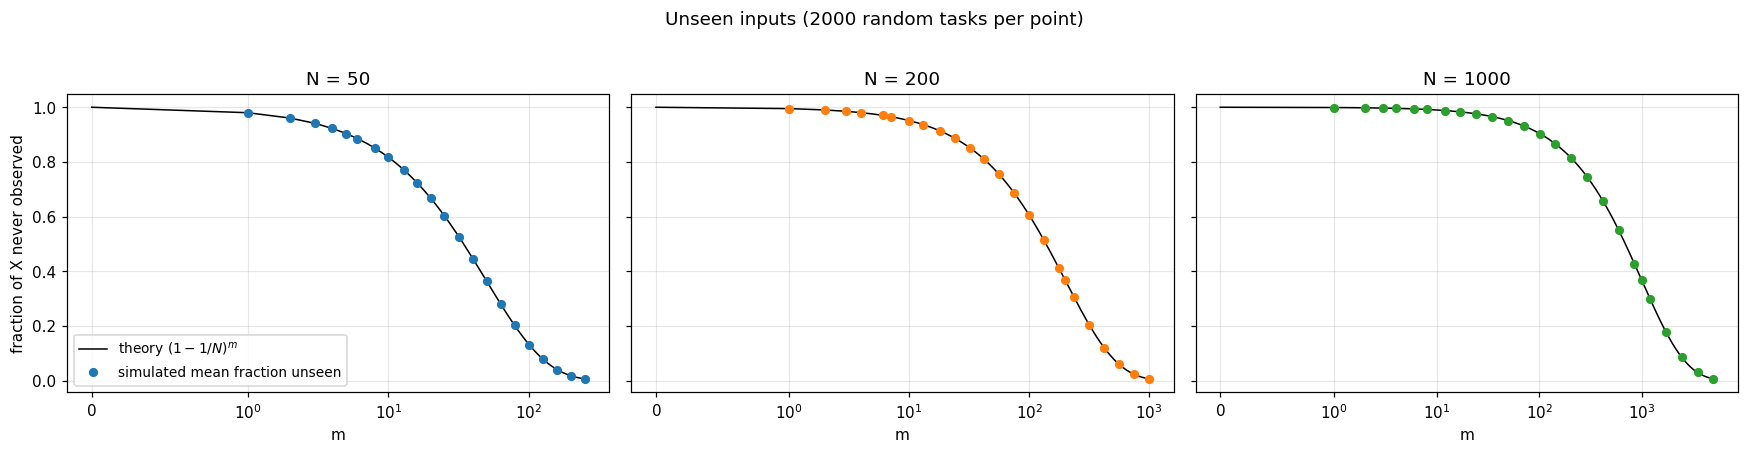

    N |     m | simulated | (1-1/N)^m
   50 |     5 |    0.9039 |    0.9039
   50 |    25 |    0.6028 |    0.6035
   50 |    50 |    0.3644 |    0.3642
   50 |   100 |    0.1322 |    0.1326
   50 |   250 |    0.0066 |    0.0064
        max |simulated - theory| over the grid = 0.0012
  200 |    18 |    0.9136 |    0.9137
  200 |   100 |    0.6056 |    0.6058
  200 |   200 |    0.3668 |    0.3670
  200 |   422 |    0.1208 |    0.1206
  200 |  1000 |    0.0067 |    0.0067
        max |simulated - theory| over the grid = 0.0010
 1000 |   101 |    0.9039 |    0.9039
 1000 |   417 |    0.6587 |    0.6589
 1000 |  1000 |    0.3676 |    0.3677
 1000 |  1724 |    0.1781 |    0.1782
 1000 |  5000 |    0.0067 |    0.0067
        max |simulated - theory| over the grid = 0.0004


In [23]:
rng = np.random.default_rng(SEED + 6)
R_NFL = 2_000
colorsN = ["tab:blue", "tab:orange", "tab:green"]

nfl = {}   # results reused in Q7 and Q10
for N in N_VALUES:
    ms = m_grid_for(N)
    out = {"m": ms, "unseen": [], "unseen_sd": [], "risk": [], "risk_sd": [], "risk_unseen": []}
    for m in ms:
        u, r, ru = run_memorization(N, m, R_NFL, rng, rules=("0",))
        out["unseen"].append(u.mean()); out["unseen_sd"].append(u.std(ddof=1))
        out["risk"].append(r["0"].mean()); out["risk_sd"].append(r["0"].std(ddof=1))
        out["risk_unseen"].append(np.nanmean(ru["0"]))
    nfl[N] = {k: np.asarray(v) for k, v in out.items()}

fig, axes = plt.subplots(1, len(N_VALUES), figsize=(16, 4), sharey=True)
for ax, N, c in zip(axes, N_VALUES, colorsN):
    d = nfl[N]
    m_fine = np.arange(0, 5 * N + 1)
    ax.plot(m_fine, (1 - 1 / N) ** m_fine, "-", color="k", lw=1, label=r"theory $(1-1/N)^m$")
    ax.plot(d["m"], d["unseen"], "o", color=c, ms=5, label="simulated mean fraction unseen")
    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(f"N = {N}")
    ax.set_xlabel("m")
axes[0].set_ylabel("fraction of X never observed")
axes[0].legend(fontsize=9)
fig.suptitle(f"Unseen inputs ({R_NFL} random tasks per point)", y=1.02)
plt.tight_layout()
plt.show()

print(f"{'N':>5} | {'m':>5} | {'simulated':>9} | {'(1-1/N)^m':>9}")
for N in N_VALUES:
    d = nfl[N]
    for m in (N // 10, N // 2, N, 2 * N, 5 * N):
        i = np.argmin(np.abs(d["m"] - m))
        print(f"{N:>5} | {d['m'][i]:>5} | {d['unseen'][i]:>9.4f} | {(1 - 1/N) ** d['m'][i]:>9.4f}")
    err = np.max(np.abs(d["unseen"] - (1 - 1 / N) ** d["m"]))
    print(f"{'':>5}   max |simulated - theory| over the grid = {err:.4f}")

**Interpretation.**

- The simulated mean fraction of unseen inputs agrees with $(1-1/N)^m$ for all $N$ and $m$ (maximum deviation $\leq 0.0012$ over the grid).
- The fraction depends essentially on $m/N$: with $m=N$ samples, $36.4\%$ to $36.8\%$ of the domain is still unobserved for every $N$ (since $(1-1/N)^N\approx e^{-1}\approx 0.368$), and $m=5N$ is needed to go below $1\%$. Because of repeated draws, a sample whose size is comparable to the size of the domain still leaves a large part of it unseen.

## 7. Error on unseen inputs



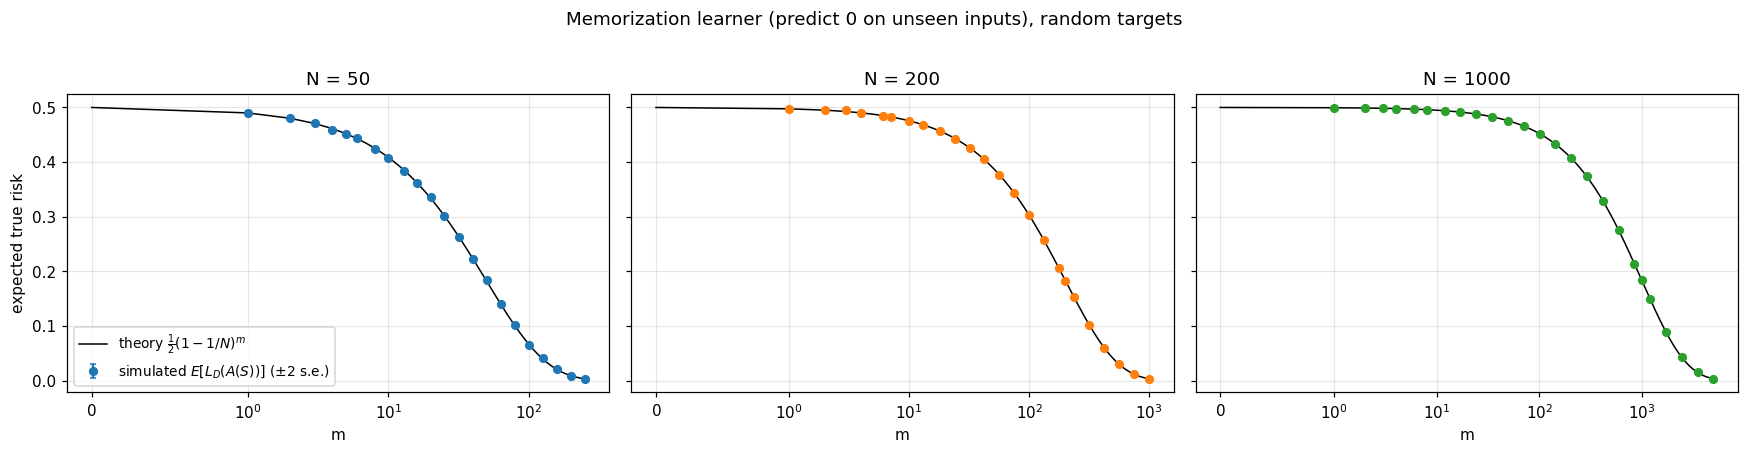

    N |     m | simulated E[L_D] |   theory
   50 |     5 |           0.4517 |   0.4520
   50 |    50 |           0.1836 |   0.1821
   50 |   100 |           0.0655 |   0.0663
        max |simulated - theory| over the grid = 0.0027
  200 |    18 |           0.4563 |   0.4569
  200 |   200 |           0.1827 |   0.1835
  200 |   422 |           0.0605 |   0.0603
        max |simulated - theory| over the grid = 0.0021
 1000 |   101 |           0.4523 |   0.4519
 1000 |  1000 |           0.1838 |   0.1838
 1000 |  1724 |           0.0890 |   0.0891
        max |simulated - theory| over the grid = 0.0007


In [24]:
fig, axes = plt.subplots(1, len(N_VALUES), figsize=(16, 4), sharey=True)
for ax, N, c in zip(axes, N_VALUES, colorsN):
    d = nfl[N]
    m_fine = np.arange(0, 5 * N + 1)
    se = d["risk_sd"] / np.sqrt(R_NFL)
    ax.plot(m_fine, 0.5 * (1 - 1 / N) ** m_fine, "-", color="k", lw=1,
            label=r"theory $\frac{1}{2}(1-1/N)^m$")
    ax.errorbar(d["m"], d["risk"], yerr=2 * se, fmt="o", color=c, ms=5, capsize=2,
                label=r"simulated $E[L_D(A(S))]$ ($\pm 2$ s.e.)")
    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(f"N = {N}")
    ax.set_xlabel("m")
axes[0].set_ylabel("expected true risk")
axes[0].legend(fontsize=9)
fig.suptitle("Memorization learner (predict 0 on unseen inputs), random targets", y=1.02)
plt.tight_layout()
plt.show()

print(f"{'N':>5} | {'m':>5} | {'simulated E[L_D]':>16} | {'theory':>8}")
for N in N_VALUES:
    d = nfl[N]
    for m in (N // 10, N, 2 * N):
        i = np.argmin(np.abs(d["m"] - m))
        print(f"{N:>5} | {d['m'][i]:>5} | {d['risk'][i]:>16.4f} | {0.5 * (1 - 1/N) ** d['m'][i]:>8.4f}")
    err = np.max(np.abs(d["risk"] - 0.5 * (1 - 1 / N) ** d["m"]))
    print(f"{'':>5}   max |simulated - theory| over the grid = {err:.4f}")

**Interpretation.**

- The simulated expected risk agrees with $\frac12(1-1/N)^m$ (maximum deviation $\leq 0.003$, within $\pm 2$ standard errors on the whole grid).
- The risk is exactly half of the fraction of unseen inputs: the learner is perfect on what it has seen and right only half of the time on everything else.
- As in Q6, the risk depends on $m/N$: at $m=N$ it is $\approx 0.18$ for all three domain sizes. Reaching a risk $\epsilon$ requires $m \approx N\ln(1/(2\epsilon))$, i.e. a number of samples proportional to the size of the domain: the learner does not generalize beyond the observed points.

## 8. Changing the prediction on unseen inputs


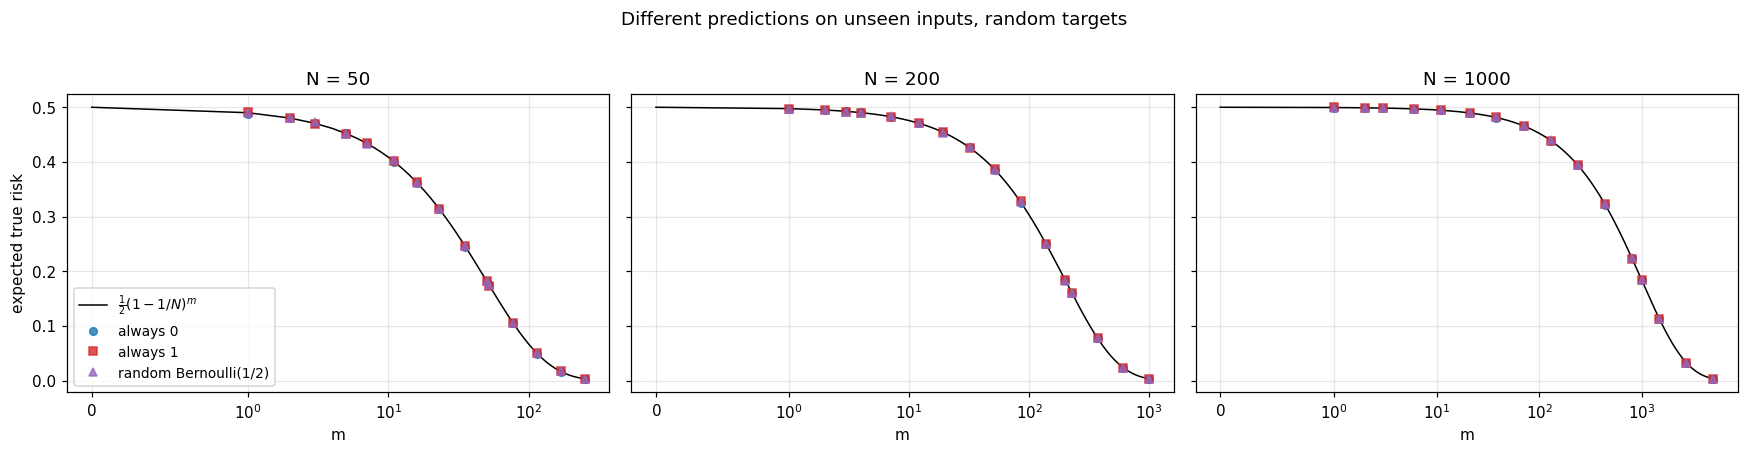

Same 2000 tasks for the three rules, m = N/2

    N |                   rule | mean risk |    s.e.
   50 |               always 0 |    0.3010 |  0.0013
   50 |               always 1 |    0.3029 |  0.0013
   50 |  random Bernoulli(1/2) |    0.3009 |  0.0013
        'always 0' beats 'always 1' on 46.8% of tasks, loses on 45.4%
        'always 0' beats 'random'   on 45.4% of tasks, loses on 45.7%
        theory: 0.5 (1-1/N)^m = 0.3017

  200 |               always 0 |    0.3019 |  0.0006
  200 |               always 1 |    0.3044 |  0.0006
  200 |  random Bernoulli(1/2) |    0.3037 |  0.0007
        'always 0' beats 'always 1' on 49.6% of tasks, loses on 46.2%
        'always 0' beats 'random'   on 49.5% of tasks, loses on 45.8%
        theory: 0.5 (1-1/N)^m = 0.3029

 1000 |               always 0 |    0.3035 |  0.0003
 1000 |               always 1 |    0.3030 |  0.0003
 1000 |  random Bernoulli(1/2) |    0.3033 |  0.0003
        'always 0' beats 'always 1' on 47.8% of tasks, loses on 

In [25]:
rng = np.random.default_rng(SEED + 8)
RULES = {"0": "always 0", "1": "always 1", "random": "random Bernoulli(1/2)"}
rule_colors = {"0": "tab:blue", "1": "tab:red", "random": "tab:purple"}

rules_res = {}
fig, axes = plt.subplots(1, len(N_VALUES), figsize=(16, 4), sharey=True)
for ax, N in zip(axes, N_VALUES):
    ms = m_grid_for(N, n_points=15)
    means = {r: [] for r in RULES}
    for m in ms:
        _, risk, _ = run_memorization(N, m, R_NFL, rng, rules=tuple(RULES))   # same (f, S) for all rules
        for r in RULES:
            means[r].append(risk[r].mean())
    m_fine = np.arange(0, 5 * N + 1)
    ax.plot(m_fine, 0.5 * (1 - 1 / N) ** m_fine, "-", color="k", lw=1, label=r"$\frac{1}{2}(1-1/N)^m$")
    for r, mk in zip(RULES, ["o", "s", "^"]):
        ax.plot(ms, means[r], mk, color=rule_colors[r], ms=5, alpha=0.8, label=RULES[r])
    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(f"N = {N}"); ax.set_xlabel("m")
axes[0].set_ylabel("expected true risk")
axes[0].legend(fontsize=9)
fig.suptitle("Different predictions on unseen inputs, random targets", y=1.02)
plt.tight_layout()
plt.show()

# Head-to-head on the same tasks, at m = N/2
print(f"Same {R_NFL} tasks for the three rules, m = N/2\n")
print(f"{'N':>5} | {'rule':>22} | {'mean risk':>9} | {'s.e.':>7}")
for N in N_VALUES:
    _, risk, _ = run_memorization(N, N // 2, R_NFL, rng, rules=tuple(RULES))
    for r in RULES:
        print(f"{N:>5} | {RULES[r]:>22} | {risk[r].mean():>9.4f} | {risk[r].std(ddof=1)/np.sqrt(R_NFL):>7.4f}")
    w01 = np.mean(risk["0"] < risk["1"]); w10 = np.mean(risk["1"] < risk["0"])
    w0r = np.mean(risk["0"] < risk["random"]); wr0 = np.mean(risk["random"] < risk["0"])
    print(f"{'':>5}   'always 0' beats 'always 1' on {w01:.1%} of tasks, loses on {w10:.1%}")
    print(f"{'':>5}   'always 0' beats 'random'   on {w0r:.1%} of tasks, loses on {wr0:.1%}")
    print(f"{'':>5}   theory: 0.5 (1-1/N)^m = {0.5 * (1 - 1/N) ** (N // 2):.4f}\n")

**Interpretation.**

- **Same expected risk.** The three curves are superposed on $\frac12(1-1/N)^m$. At $m=N/2$, the mean risks are between $0.301$ and $0.304$ for every rule and every $N$ (theory $\approx 0.302$–$0.303$). The small differences are of the order of the Monte-Carlo error and the best rule changes with $N$ (random at $N=50$, always 0 at $N=200$, always 1 at $N=1000$).
- **No consistent winner.** On the same tasks, "always 0" beats "always 1" on about half of the tasks and loses on the other half ($46.8\%/45.4\%$, $49.6\%/46.2\%$, $47.8\%/50.6\%$; the rest are ties). The same holds against the random rule.
- **Why.** On an unseen input, the rule has no information on $f(x)$: labels are independent across inputs, and $f(x)$ is not in the sample. Whatever the prediction $g(x)\in\{0,1\}$ (fixed or random, but independent of $f(x)$), $\Pr[g(x)\neq f(x)] = 1/2$. Hence every rule has expected risk $\frac12(1-1/N)^m$.
- **Link with No-Free-Lunch.** Averaged over all target functions, every learner has the same expected error on the inputs it has not seen: $1/2$, i.e. no better than random guessing. A rule that does well on a target $f$ does equally badly on the target that flips $f$ on the unseen inputs, and both targets are equally likely. The training sample alone carries no information about unseen labels; doing better requires assumptions on the target (Part III).

---
# Part III – Introducing Prior Knowledge



In [26]:
def run_threshold_erm(N, m, R, rng):
    """R independent tasks on X = {1, ..., N}, uniform D, threshold target f_theta(x) = 1[x > theta],
    theta ~ Uniform{1, ..., N-1}. ERM over H = {h_t(x) = 1[x > t] : t = 1, ..., N-1}
    (ties between empirical minimizers broken by taking the smallest t).
    Returns the true risk L_D(h_S), the fraction of unseen inputs and the error rate on unseen inputs."""
    theta = rng.integers(1, N, size=R)                  # theta in {1, ..., N-1}
    X_S = rng.integers(1, N + 1, size=(R, m))           # S ~ D^m, x in {1, ..., N}
    Y_S = (X_S > theta[:, None]).astype(int)            # y_i = f_theta(x_i)

    # counts n1[r, x] / n0[r, x] of sample points at x with label 1 / 0
    flat = (np.arange(R)[:, None] * (N + 1) + X_S).ravel()
    n1 = np.bincount(flat, weights=Y_S.ravel(), minlength=R * (N + 1)).reshape(R, N + 1)
    n0 = np.bincount(flat, weights=1 - Y_S.ravel(), minlength=R * (N + 1)).reshape(R, N + 1)
    c1, c0 = np.cumsum(n1, axis=1), np.cumsum(n0, axis=1)

    # empirical risk of every h_t: label-1 points with x <= t + label-0 points with x > t
    t = np.arange(1, N)
    emp_risk = (c1[:, t] + (c0[:, [N]] - c0[:, t])) / m
    t_hat = t[np.argmin(emp_risk, axis=1)]              # ERM

    x = np.arange(1, N + 1)
    err = (x[None, :] > t_hat[:, None]) != (x[None, :] > theta[:, None])
    risk = err.mean(axis=1)                             # L_D(h_S) over the complete domain
    unseen = (n0 + n1)[:, 1:] == 0
    n_unseen = unseen.sum(axis=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        risk_unseen = np.where(n_unseen > 0, (err & unseen).sum(axis=1) / n_unseen, np.nan)
    return risk, n_unseen / N, risk_unseen

## 9. Learning with a matching inductive bias



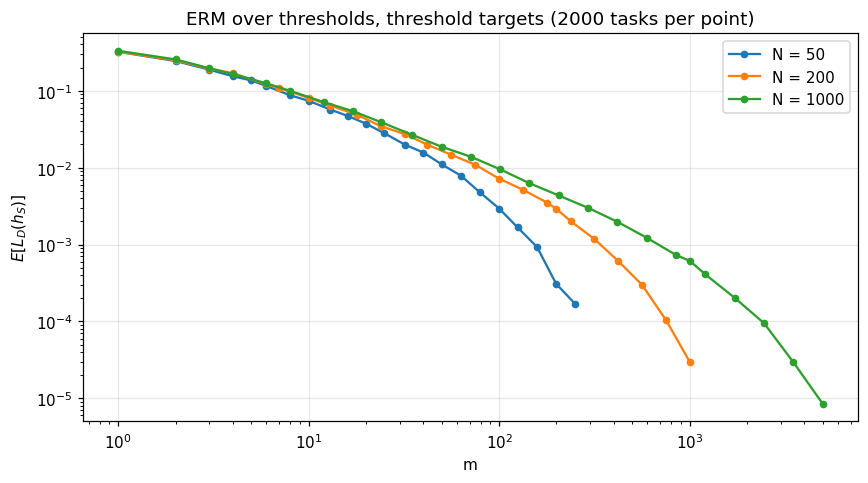

    N |     m | thresholds: E[L_D(h_S)] |  random targets (Part II): E[L_D(A(S))]
   50 |     5 |                  0.1360 |                                  0.4517
   50 |    10 |                  0.0740 |                                  0.4081
   50 |    50 |                  0.0110 |                                  0.1836
   50 |   100 |                  0.0029 |                                  0.0655
  200 |    10 |                  0.0805 |                                  0.4761
  200 |    18 |                  0.0485 |                                  0.4563
  200 |   200 |                  0.0029 |                                  0.1827
  200 |   422 |                  0.0006 |                                  0.0605
 1000 |     8 |                  0.0995 |                                  0.4962
 1000 |   101 |                  0.0095 |                                  0.4523
 1000 |  1000 |                  0.0006 |                                  0.1838
 1000 |  1724 | 

In [27]:
rng = np.random.default_rng(SEED + 9)
R_THR = 2_000

thr = {}   # results reused in Q10
for N in N_VALUES:
    ms = nfl[N]["m"]                                    # same sample sizes as Part II
    out = {"m": ms, "risk": [], "risk_sd": [], "unseen": [], "risk_unseen": []}
    for m in ms:
        r, u, ru = run_threshold_erm(N, m, R_THR, rng)
        out["risk"].append(r.mean()); out["risk_sd"].append(r.std(ddof=1))
        out["unseen"].append(u.mean()); out["risk_unseen"].append(np.nanmean(ru))
    thr[N] = {k: np.asarray(v) for k, v in out.items()}

fig, ax = plt.subplots(figsize=(8, 4.5))
for N, c in zip(N_VALUES, colorsN):
    ax.plot(thr[N]["m"], pos(thr[N]["risk"]), "o-", color=c, ms=4, label=f"N = {N}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("m"); ax.set_ylabel(r"$E[L_D(h_S)]$")
ax.set_title(f"ERM over thresholds, threshold targets ({R_THR} tasks per point)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'N':>5} | {'m':>5} | {'thresholds: E[L_D(h_S)]':>23} | {'random targets (Part II): E[L_D(A(S))]':>39}")
for N in N_VALUES:
    for i in sorted({int(np.argmin(np.abs(thr[N]["m"] - m))) for m in (10, N // 10, N, 2 * N)}):
        print(f"{N:>5} | {thr[N]['m'][i]:>5} | {thr[N]['risk'][i]:>23.4f} | {nfl[N]['risk'][i]:>39.4f}")

**Interpretation.**

- **Much smaller risk than with random targets.** With only $m\approx10$ samples the expected risk is $0.07$–$0.10$, versus $0.41$–$0.50$ for random targets. At $m=N$ it is $0.011$ ($N=50$), $0.0029$ ($N=200$), $0.0006$ ($N=1000$), versus $\approx 0.18$ for random targets.
- **Decay like $1/m$, independently of $N$.** On the log-log plot the curves have a slope close to $-1$ ($E[L_D(h_S)]$ is divided by about 10 when $m$ is multiplied by 10), and the curves for the three domain sizes coincide as long as $m\ll N$: the risk depends on $m$, not on the size of the domain. With random targets, it depended on $m/N$.
- When $m$ approaches $N$ the risk drops faster: in a finite domain the inputs adjacent to $\theta$ end up being sampled, and ERM then returns exactly $\theta$.

## 10. Random targets vs structured targets



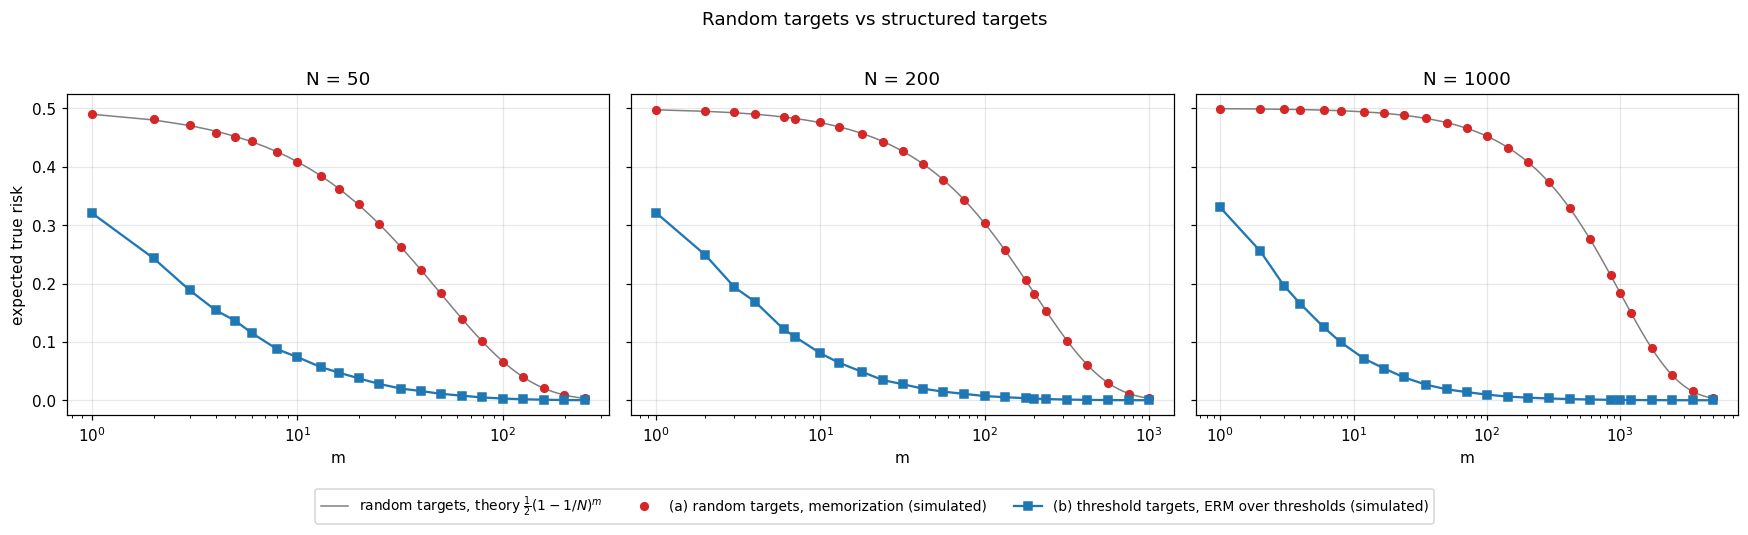

Behaviour on the inputs that were NOT in the training sample

    N |     m | fraction unseen | error on unseen (a) random | error on unseen (b) thresholds
   50 |     5 |           0.904 |                     0.4997 |                         0.1503
   50 |    25 |           0.603 |                     0.4996 |                         0.0461
   50 |    50 |           0.362 |                     0.5035 |                         0.0302
  200 |    18 |           0.914 |                     0.4994 |                         0.0530
  200 |   100 |           0.605 |                     0.5014 |                         0.0118
  200 |   200 |           0.368 |                     0.4981 |                         0.0079
 1000 |   101 |           0.904 |                     0.5004 |                         0.0106
 1000 |   417 |           0.659 |                     0.4999 |                         0.0030
 1000 |  1000 |           0.368 |                     0.5001 |                         0.001

In [28]:
fig, axes = plt.subplots(1, len(N_VALUES), figsize=(16, 4.2), sharey=True)
for ax, N in zip(axes, N_VALUES):
    m_fine = np.arange(1, 5 * N + 1)
    ax.plot(m_fine, 0.5 * (1 - 1 / N) ** m_fine, "-", color="gray", lw=1,
            label=r"random targets, theory $\frac{1}{2}(1-1/N)^m$")
    ax.plot(nfl[N]["m"], nfl[N]["risk"], "o", color="tab:red", ms=5,
            label="(a) random targets, memorization (simulated)")
    ax.plot(thr[N]["m"], thr[N]["risk"], "s-", color="tab:blue", ms=5,
            label="(b) threshold targets, ERM over thresholds (simulated)")
    ax.set_xscale("log")
    ax.set_title(f"N = {N}"); ax.set_xlabel("m")
axes[0].set_ylabel("expected true risk")
fig.suptitle("Random targets vs structured targets", y=1.02)
plt.tight_layout()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=9, bbox_to_anchor=(0.5, 0.0))
plt.show()

print("Behaviour on the inputs that were NOT in the training sample\n")
print(f"{'N':>5} | {'m':>5} | {'fraction unseen':>15} | {'error on unseen (a) random':>26} | {'error on unseen (b) thresholds':>30}")
for N in N_VALUES:
    for m in (N // 10, N // 2, N):
        i = np.argmin(np.abs(nfl[N]["m"] - m))
        print(f"{N:>5} | {nfl[N]['m'][i]:>5} | {thr[N]['unseen'][i]:>15.3f} | "
              f"{nfl[N]['risk_unseen'][i]:>26.4f} | {thr[N]['risk_unseen'][i]:>30.4f}")

**Interpretation.**

- **Generalization to unseen inputs.** With random targets, the error on unseen inputs stays at $\approx 0.50$ for every $N$ and $m$: the learner only knows what it has seen. With threshold targets, the error on unseen inputs is small and decreases with $m$: for $N=1000$ and $m=101$, $90\%$ of the domain was never observed, yet the hypothesis returned by ERM is wrong on only $1.1\%$ of these unseen inputs.
- **Why.** The assumption $f\in\{\text{thresholds}\}$ links the labels of different inputs: $f(x)=0$ for every $x\leq\theta$ and $f(x)=1$ for every $x>\theta$. If the sample contains an input $x_0$ labelled 0 and an input $x_1$ labelled 1, then every $x\leq x_0$ has label 0 and every $x\geq x_1$ has label 1, seen or not. Only the inputs between the largest observed 0 and the smallest observed 1 remain uncertain; this gap has an expected length of order $N/m$, which explains a risk of order $1/m$. With random targets, $f(x)$ on an unseen input is independent of the whole sample, so nothing can be transferred from seen to unseen inputs.
- **Role of the assumption.** It reduces the set of possible targets from all $2^N$ labelings to $N-1$ threshold functions, and the hypothesis class is restricted accordingly. In the terms of Part I, $\log|H| = \log(N-1)$ instead of $N\log 2$ for the class of all labelings: the sample size needed becomes logarithmic in $N$ instead of proportional to $N$. The improvement relies on the target actually belonging to the assumed family: the guarantee obtained from ERM over thresholds only covers threshold targets.

---
# 11. Final Analysis

- **Concentration of $L_S(h)$ around $L_D(h)$.** $L_S(h)$ is an average of $m$ independent losses in $[0,1]$ with mean $L_D(h)$ and variance $p(1-p)/m$. Its standard deviation decreases like $1/\sqrt{m}$ (Q1: from $0.143$ at $m=10$ to $0.0065$ at $m=5000$) and the probability of a deviation larger than $\epsilon$ decreases exponentially with $m$ (Q2), as stated by Hoeffding.
- **Simultaneous control over all hypotheses.** A learner selects its hypothesis using empirical risks, so a guarantee on the selected hypothesis requires every $|L_S(h)-L_D(h)|$ to be small at the same time. This event is much less likely than the corresponding event for a single hypothesis (Q3: at $m\approx200$, $0.66$ for $\Delta_S$ against $0.16$ for the worst single hypothesis).
- **Effect of $|H|$.** Each additional hypothesis is an additional chance of a large deviation: $\Pr[\Delta_S>\epsilon]$ increases with $|H|$ and more data are needed (Q4). The increase is only logarithmic: the required sample size grows linearly in $\log|H|$ (Q5: $\approx173$ samples per unit of $\log|H|$ experimentally, $200$ in theory; $\times100$ on $|H|$ gives $\times2.5$ on $m$).
- **Conservative bounds.** The finite-class bound combines Hoeffding (worst-case variance $1/4$) and the union bound (deviation events treated as disjoint), and it must hold for every class of size $|H|$ and every distribution. It is always valid in our experiments but overestimates the probabilities (by a factor 2.6 to 100 in Q2) and the required sample size (by a factor 1.5 to 2 in Q5): it is a sufficient condition, not the exact minimum.
- **Random targets make unseen labels unpredictable.** When $f(x)\sim\mathrm{Bernoulli}(1/2)$ independently, the sample contains no information about $f$ on unseen inputs; any prediction there is wrong with probability $1/2$. This gives $\mathbb{E}[L_D(A(S))]=\frac12(1-1/N)^m$, confirmed by simulation (Q6–Q7), with an error on unseen inputs that stays at $0.50$ (Q10).
- **No-Free-Lunch.** Changing the prediction rule on unseen inputs changes nothing on average, and no rule wins consistently on the same tasks (Q8). Without assumptions on the target, a learner cannot infer unseen labels from the training sample: the only way to reduce the risk is to observe the inputs, which requires a sample size proportional to $N$ (several times $N$ to make the risk small).
- **Prior knowledge through thresholds.** Assuming that the target is a threshold, and restricting the hypothesis class to thresholds, is a choice made before seeing the data. It reduces the possible targets from $2^N$ arbitrary labelings to $N-1$ structured functions.
- **Why this inductive bias allows generalization.** Under the threshold structure, the observed labels determine the labels of all unseen inputs except those in a small gap around $\theta$. ERM therefore reaches a risk of order $1/m$, independent of $N$ (Q9), and is right on about $99\%$ of the unseen inputs when $90\%$ of the domain is unseen (Q10, $N=1000$). This is consistent with Part I: a small class ($\log|H|=\log(N-1)$) needs few samples. The bias helps because it matches the target; No-Free-Lunch says that this gain is only possible for the family of targets the learner is biased towards.